# Masked-sky rotation reconstruction: with and without miscalibration
Single-frequency comparison at **nside=512**, **lmax_ivf=lmax_qlm=1024** using the existing isotropic filter.

Read **field 2 (zero-based, the third column)** of `binary_GAL_mask_N1024.fits`. Downgrade the mask from nside 1024 to 512 with `hp.ud_grade`; fractional edge weights are retained. The observation is
$$m_\nu^{\rm obs}=M\,[B_\nu\,R(\alpha_\nu)R(a(\hat n))m_{\rm CMB}+n_\nu].$$
The mask acts at the very last step, including on noise. Compare `alpha=None` with `alpha=0.2` **degrees**, retaining the same spatial rotation amplitude `Acb` and realization seeds. “Without alpha” here means no constant instrumental miscalibration, not removal of the anisotropic field.

**Interpretation:** the filter, full-sky QE response, and existing noise estimate are unchanged. Plotted reconstructed spectra are masked-sky diagnostics: no mean-field subtraction, mode-coupling correction, empirical response calibration, or sky-fraction rescaling is applied. The analytic full-sky input is a reference, not an exact prediction for the masked estimator.

In [1]:
%matplotlib inline
import hashlib
import json
from pathlib import Path
import time

import healpy as hp
import numpy as np
import matplotlib.pyplot as plt
from sim import CMBobs
from recon import AlphaRecon

plt.rcParams.update({'figure.dpi':120, 'axes.grid':True, 'grid.alpha':0.2})
nside = 512
lmax_ivf = 1024
lmax_qlm = 1024
lmin_ivf = 20
nlevp = 2.0       # uK-arcmin
fwhm = 8.0        # arcmin
Acb = 1e-6        # shared anisotropic rotation, rad²
alpha_deg = 0.2   # constant channel miscalibration, degrees
sim_indices = tuple(range(4))
bin_width = 32
mask_path = Path('binary_GAL_mask_N1024.fits')
mask_field = 2
assert mask_path.exists(), f'Place the supplied mask at {mask_path.resolve()}'
assert len(sim_indices) >= 2

native_mask = hp.read_map(str(mask_path), field=mask_field, dtype=float)
assert hp.npix2nside(native_mask.size) == 1024
mask = hp.ud_grade(native_mask, nside, order_in='RING', order_out='RING')
del native_mask
kwargs = dict(nside=nside, nlevp=nlevp, fwhm=fwhm, Acb=Acb, mask=mask)
obs_none = CMBobs(alpha=None, **kwargs)
obs_alpha = CMBobs(alpha=alpha_deg, **kwargs)
np.testing.assert_array_equal(obs_none.mask, mask)
np.testing.assert_array_equal(obs_alpha.mask, mask)
config = dict(nside=nside,lmax_ivf=lmax_ivf,lmax_qlm=lmax_qlm,lmin_ivf=lmin_ivf,
              nlevp=nlevp,fwhm=fwhm,Acb=Acb,alpha_deg=alpha_deg,
              mask_sha256=hashlib.sha256(mask.tobytes()).hexdigest())
tag = hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:16]
root = Path('data')/'masked_reconstruction'/tag
rec_kwargs = dict(lmin_ivf=lmin_ivf,lmax_ivf=lmax_ivf,lmax_qlm=lmax_qlm)
rec_none = AlphaRecon(obs_none,root/'no_alpha',**rec_kwargs)
rec_alpha = AlphaRecon(obs_alpha,root/'with_alpha',**rec_kwargs)
# Verify that only the simulated maps differ; the current filters are identical.
for name in ['get_ftl','get_fel','get_fbl']:
    np.testing.assert_array_equal(getattr(rec_none.ivfs,name)(),getattr(rec_alpha.ivfs,name)())
f1,f2,f4 = [np.mean(mask**power) for power in [1,2,4]]
print(f'Mask field {mask_field}: mean(M)={f1:.6f}, mean(M²)={f2:.6f}, mean(M⁴)={f4:.6f}')
print(f'Fractional boundary pixels: {np.count_nonzero((mask>0)&(mask<1))}')
print('Both filters unchanged; no sky-fraction normalization applied.')
print('Cache:',root)

Caching sky fractions...
Caching sky fractions...
Mask field 2: mean(M)=0.700125, mean(M²)=0.699849, mean(M⁴)=0.699628
Fractional boundary pixels: 4279
Both filters unchanged; no sky-fraction normalization applied.
Cache: data/masked_reconstruction/def01895775c3f86


/Users/antoidicherianlonappan/Software/plancklens/plancklens/utils.py:124: RuntimeWarning: overflow encountered in cast
  return hashlib.sha1(np.copy(cl.astype(dtype), order='C')).hexdigest()


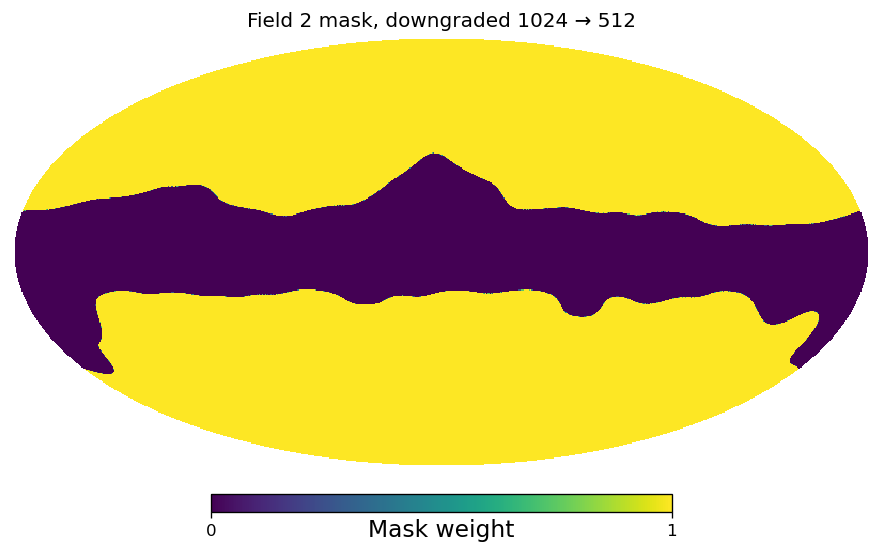

Verified: masked map = mask × (beam-smoothed rotated CMB + noise).


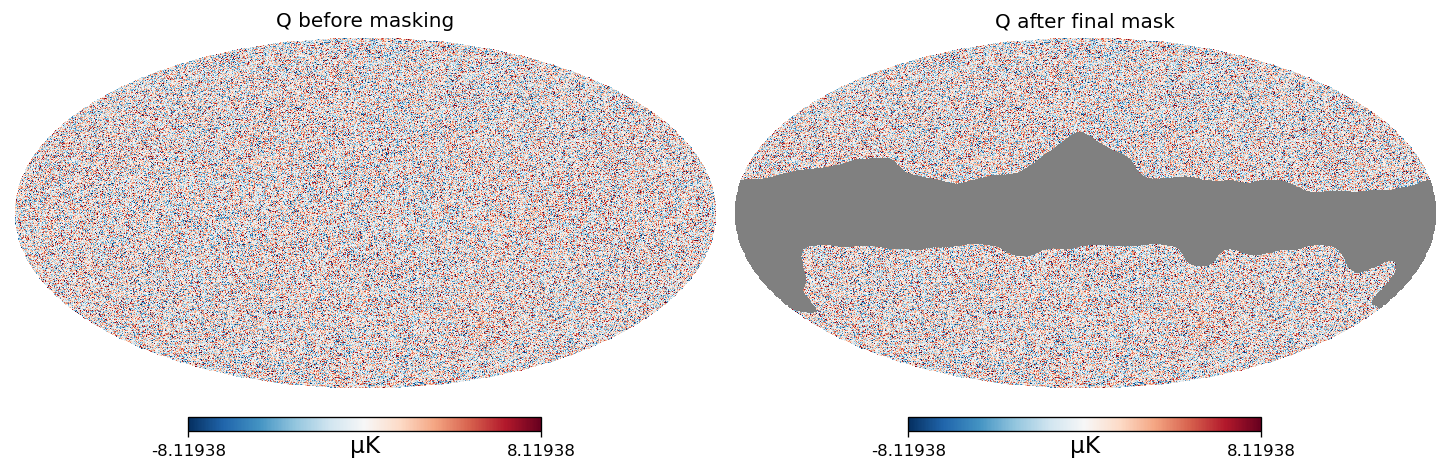

In [2]:
fig=plt.figure(figsize=(8,4.7))
hp.mollview(mask,fig=fig.number,title='Field 2 mask, downgraded 1024 → 512',
            unit='Mask weight',min=0,max=1,cmap='viridis')
plt.show()

# Check the final operation at the requested analysis resolution.
idx=sim_indices[0]
full_obs=CMBobs(nside,nlevp,fwhm,alpha=alpha_deg,Acb=Acb)
full_map=full_obs.observedmap(idx)[0]
masked_map=obs_alpha.observedmap(idx)[0]
np.testing.assert_array_equal(masked_map,full_map*mask)
np.testing.assert_array_equal(obs_alpha.noise_map(idx,0),full_obs.noise_map(idx,0)*mask)
assert np.all(masked_map[:,mask==0]==0)
print('Verified: masked map = mask × (beam-smoothed rotated CMB + noise).')
fig=plt.figure(figsize=(12,4.5))
limit=np.percentile(np.abs(full_map[1]),99)
for panel,sky,title in [(1,full_map[1],'Q before masking'),(2,masked_map[1],'Q after final mask')]:
    shown=sky.copy()
    if panel==2: shown[mask==0]=hp.UNSEEN
    hp.mollview(shown,fig=fig.number,sub=(1,2,panel),title=title,
                unit='µK',min=-limit,max=limit,cmap='RdBu_r')
plt.show()
del full_obs,full_map,masked_map

## Matched reconstruction ensemble
Each pair uses identical CMB, spatial rotation, and noise seeds. Only the constant miscalibration differs. The truth alms below describe the common full-sky anisotropic field; cross-spectra measure how the masked reconstruction responds to it.

The existing `AlphaRecon.noise_spectrum` is a full-sky semi-analytical estimate applied to masked data. Its subtraction is displayed as a diagnostic only; it is not a calibrated cut-sky bias subtraction.

In [3]:
L=np.arange(lmax_qlm+1)
cl_aa=obs_none.cl_aa()[:lmax_qlm+1]
ells,ms=hp.Alm.getlm(lmax_qlm)
selection=hp.Alm.getidx(obs_none.lmax,ells,ms)
results={case:{key:[] for key in ['auto','cross','n0']} for case in ['no_alpha','with_alpha']}
input_cls=[]
start=time.perf_counter()
for idx in sim_indices:
    truth=obs_none.alpha_alm(idx)[selection]
    input_cls.append(hp.alm2cl(truth))
    for case,rec in [('no_alpha',rec_none),('with_alpha',rec_alpha)]:
        estimate=rec.reconstruct(idx)
        results[case]['auto'].append(hp.alm2cl(estimate))
        results[case]['cross'].append(hp.alm2cl(estimate,truth))
        results[case]['n0'].append(rec.noise_spectrum(idx))
        print(f'{case}, idx={idx}, elapsed={time.perf_counter()-start:.1f} s',flush=True)
results={case:{key:np.asarray(value) for key,value in values.items()}
         for case,values in results.items()}
input_cls=np.asarray(input_cls)
assert all(np.isfinite(value).all() for values in results.values() for value in values.values())
np.savez(root/'comparison_cls.npz',ell=L,theory=cl_aa,input=input_cls,
         indices=np.array(sim_indices),**{f'{case}_{key}':value
             for case,values in results.items() for key,value in values.items()})
print('Saved raw spectra:',root/'comparison_cls.npz')

no_alpha, idx=0, elapsed=4.6 s


with_alpha, idx=0, elapsed=9.3 s


no_alpha, idx=1, elapsed=14.0 s


with_alpha, idx=1, elapsed=18.7 s


no_alpha, idx=2, elapsed=23.5 s


with_alpha, idx=2, elapsed=28.2 s


no_alpha, idx=3, elapsed=33.1 s


with_alpha, idx=3, elapsed=38.7 s


Saved raw spectra: data/masked_reconstruction/def01895775c3f86/comparison_cls.npz


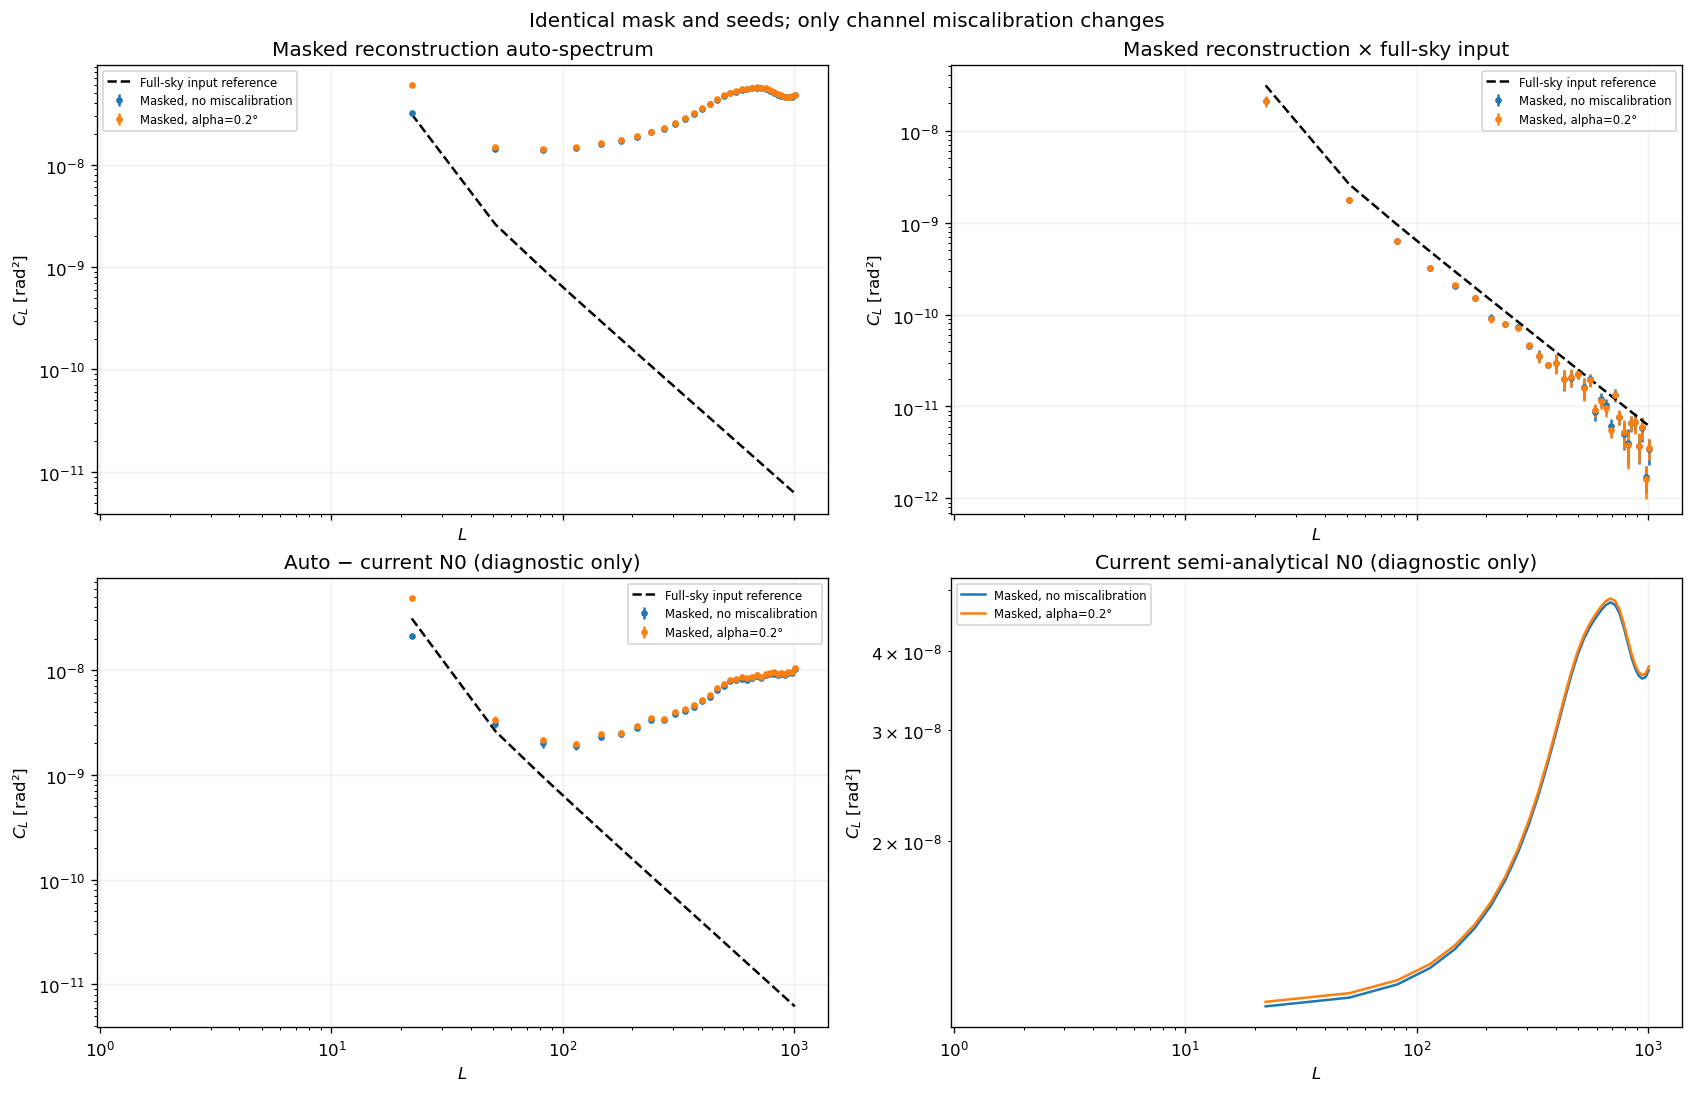

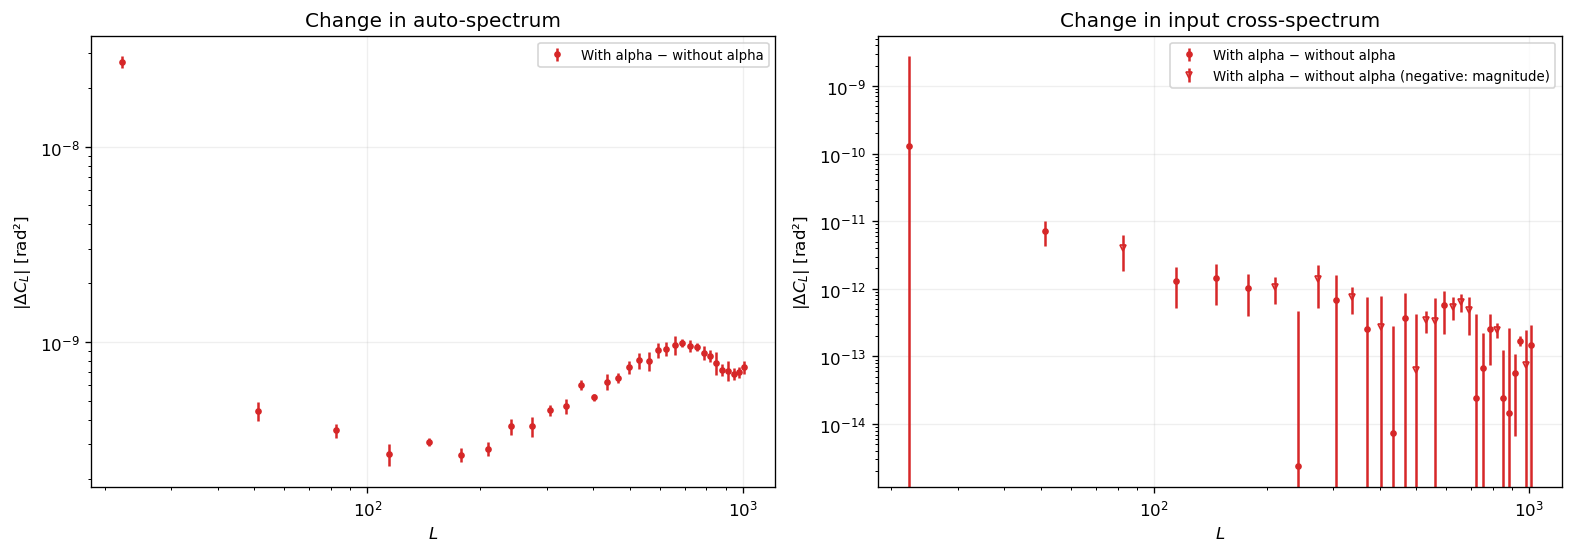

Open downward triangles denote NEGATIVE bandpowers plotted by magnitude.


In [4]:
edges=np.append(np.arange(2,lmax_qlm+1,bin_width),lmax_qlm+1)
bins=[np.arange(a,b) for a,b in zip(edges[:-1],edges[1:])]
weights=[(2*b+1)/np.sum(2*b+1) for b in bins]
L_b=np.array([np.sum(b*w) for b,w in zip(bins,weights)])
def bin_cl(cls):
    # Raw C_L: no L(L+1)/(2pi) factor.
    return np.stack([np.sum(cls[...,b]*w,axis=-1) for b,w in zip(bins,weights)],axis=-1)
def mean_sem(samples):
    return samples.mean(0),samples.std(0,ddof=1)/np.sqrt(len(samples))
def log_points(ax,x,y,err,label,color):
    pos,neg=y>0,y<0
    ax.errorbar(x[pos],y[pos],err[pos],fmt='o',ms=3,color=color,label=label)
    if neg.any():
        ax.errorbar(x[neg],-y[neg],err[neg],fmt='v',mfc='none',ms=4,color=color,
                    label=label+' (negative: magnitude)')
    ax.set(xscale='log',yscale='log')

np.testing.assert_allclose(bin_cl(np.ones_like(cl_aa)),1)
bands={case:{key:bin_cl(value) for key,value in values.items()} for case,values in results.items()}
theory_b=bin_cl(cl_aa)
fig,axes=plt.subplots(2,2,figsize=(14,9),sharex=True,layout='constrained')
for case,label,color in [('no_alpha','Masked, no miscalibration','C0'),
                          ('with_alpha',f'Masked, alpha={alpha_deg:g}°','C1')]:
    b=bands[case]
    for ax,values in [(axes[0,0],b['auto']),(axes[0,1],b['cross']),
                      (axes[1,0],b['auto']-b['n0'])]:
        mean,err=mean_sem(values)
        log_points(ax,L_b,mean,err,label,color)
    axes[1,1].loglog(L_b,b['n0'].mean(0),color=color,label=label)
for ax in [axes[0,0],axes[0,1],axes[1,0]]:
    ax.loglog(L_b,theory_b,'k--',label='Full-sky input reference')
for ax,title in zip(axes.flat,['Masked reconstruction auto-spectrum',
                              'Masked reconstruction × full-sky input',
                              'Auto − current N0 (diagnostic only)',
                              'Current semi-analytical N0 (diagnostic only)']):
    ax.set(title=title,xlabel='$L$',ylabel=r'$C_L$ [rad²]')
    ax.legend(fontsize=7)
fig.suptitle('Identical mask and seeds; only channel miscalibration changes')
plt.show()

# Paired differences retain the correlation between the two cases.
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
for ax,key,title in zip(axes,['auto','cross'],['Change in auto-spectrum','Change in input cross-spectrum']):
    difference=bands['with_alpha'][key]-bands['no_alpha'][key]
    mean,err=mean_sem(difference)
    log_points(ax,L_b,mean,err,'With alpha − without alpha','C3')
    ax.set(title=title,xlabel='$L$',ylabel=r'$|\Delta C_L|$ [rad²]')
    ax.legend(fontsize=8)
plt.show()
print('Open downward triangles denote NEGATIVE bandpowers plotted by magnitude.')

## Scope of this comparison
The pipeline retains the original isotropic filter and full-sky response as requested. A mask introduces mode coupling, E/B mixing, and a reconstruction mean field. A constant calibration angle can consequently affect modes beyond L=0. Neither the raw nor N0-subtracted spectra here are an unbiased cut-sky measurement of the injected $C_L^{\alpha\alpha}$.

The paired comparison isolates the change caused by constant miscalibration under this exact mask and filter. For a calibrated cut-sky spectrum, additional mean-field, response/mode-coupling, and noise-bias validation would be needed. No D-factor or undocumented sky-fraction correction is used. Error bars show the standard error across the four matched realizations; negative bins are explicitly marked on log–log axes.